# Model Setup

In [110]:
# --- Packages ---

import numpy as np
import numdifftools as nd
import pandas as pd
import seaborn as sns

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates

import scipy as sp
from scipy.optimize import minimize
from scipy.integrate import solve_ivp
from scipy import stats

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf

mpl.rcParams.update(mpl.rcParamsDefault)

# -----

In [3]:
# --- Spain Data ---

df = pd.read_csv("spain_ag.csv")

df["ISO_WEEKSTARTDATE"] = pd.to_datetime(df['ISO_WEEKSTARTDATE'], format='%Y-%m-%d')

df = df.rename(columns = {"ISO_WEEKSTARTDATE": "week_start",
                          "ILI_CASE" : "positive"})

# -----

In [4]:
# --- Seasonal Transmission Rate Function ---

def beta_t(t, log_beta, amp, phase):

    """
    Calculate the transmission rate at time t.
    
    Parameters:
        t        : Time in days since the start of the simulation.
        log_beta : Log baseline transmission rate.
        amp      : Seasonal amplitude on the log-transmission scale.
        phase    : Phase shift controlling the timing of the peak.
        
    Returns:
        beta_t   : Time-varying transmission rate.
    """

    # Seasonal component (log-transmission scale)
    seasonal_term = amp * np.cos(2 * np.pi * t / 365 - phase)

    # Baseline + seasonal variation
    log_beta_t = log_beta + seasonal_term

    return np.exp(log_beta_t)
  
# -----

In [5]:
# --- Fixed Transition Rate Function ---

def set_rate(sigma, gamma):
    
    """ 
    Function returning the transition rates out of E and I. 
    
    Parameters:
        sigma   : Rate of progression from exposed to infectious.
        gamma   : Rate of recovery from infectious to recovered.
    
    Returns:
        rate_fn : Outflows sigma * E and gamma * I for a given state.
    """

    def rate_fn(state):

        S, E, I, R = state    # unpack states

        # Flows out of E and I compartments
        sigma_E = sigma * E
        gamma_I = gamma * I
        
        return [sigma_E, gamma_I]
        
    return rate_fn

# -----

In [6]:
# --- Season Boundaries ---

def get_season_boundaries(start_year, n_seasons, burn_in_seasons):
    
    """
    Calculate the day boundaries of influenza seasons.
    
    Each season runs from Monday of ISO week 40 to the start of week 40 in the following year.

    Parameters:
        start_year        : Calendar year in which the first *observed* season starts.
        n_seasons         : Number of observed seasons.
        burn_in_seasons   : Number of preceding seasons simulated as burn-in.

    Returns:
        season_boundaries : Array of the season boundaries (days) since the start of the simulation.
                            Includes the initial boundary and final endpoint.
    """

    first_year = start_year - burn_in_seasons    # first year of whole simulation

    # Find Monday W40 for each season inc. final endpoint
    season_starts = [pd.Timestamp.fromisocalendar(year, 40, 1) 
                     for year in range(first_year, start_year + n_seasons + 1)]

    # Convert calendar dates into days since the first day
    season_boundaries = np.array([(date - season_starts[0]).days 
                                   for date in season_starts])

    return season_boundaries

# -----

In [7]:
# --- Construct Log Omega_s Vector ---

def make_log_omega_s(log_omega0, W_s, total_seasons, burn_in_seasons):
    
    """
    Construct the log immunity-loss rate for each influenza season.

    Burn-in seasons use the baseline log rate log_omega0.
    Observed seasons use log_omega0 plus a season-specific random effect.

    Parameters:
        log_omega0      : Baseline log immunity-loss rate.
        W_s             : Random effects for the observed seasons.
        total_seasons   : Total seasons, including burn-in.
        burn_in_seasons : Number of burn-in seasons.

    Returns:
        log_omega_s     : Log immunity-loss rate for each season.
    """
    
    log_omega_s = []    # storage
    
    for s in range(total_seasons):
        
        if s < burn_in_seasons:
            # Burn-in: use just baseline
            log_omega_s.append(log_omega0)
            
        else:
            # Observed seasons: use baseline + random effect
            idx = s - burn_in_seasons
            log_omega_s.append(log_omega0 + W_s[idx])
    
    return log_omega_s

# -----

In [8]:
# --- SEIRS Function + Seasonal Indexing ---

def seirs(t, state, log_beta, amp, phase, log_omega_s, rate_fn, season_boundaries):

    """
    Define the SEIRS ordinary differential equations.

    Transmission varies continuously with time, while the immunity-loss rate is constant within each influenza season.

    Parameters:
        t                 : Time in days since the start of the simulation.
        state             : Current numbers of susceptible, exposed, infectious and recovered individuals.
        log_beta          : Log baseline transmission rate.
        amp               : Seasonal amplitude on the log-transmission scale.
        phase             : Phase shift controlling the timing of the peak.
        log_omega_s       : Log immunity-loss rate for each influenza season.
        rate_fn           : Returns the exposed-to-infectious and recovery flows.
        season_boundaries : Day boundaries of the influenza seasons.

    Returns:
        list              : derivatives dS/dt, dE/dt, dI/dt and dR/dt.
    """
    
    S, E, I, R = state    # unpack state
    N = S + E + I + R    # total population size (constant)

    # Transmission rate at time t
    b_t = beta_t(t, log_beta, amp, phase)

    # Outflows: E -> I and I -> R
    sigmaE, gammaI = rate_fn(state)

    # Identify the season containing time t; at a boundary, assign t to the new season.
    t_index = np.searchsorted(season_boundaries, t, side="right") - 1

    # Retrieve season specific log-immunity loss and convert to the rate scale
    omega = np.exp(log_omega_s[t_index])

    # SEIRS differential equations
    dS = -b_t * S * I / N + omega * R
    dE =  b_t * S * I / N - sigmaE
    dI =  sigmaE - gammaI
    dR =  gammaI - omega * R

    return [dS, dE, dI, dR]

# -----

In [9]:
# --- Simulate SEIRS: Daily Sim -> Weekly Inc ---

def sim_seirs(state, log_beta, amp, phase, log_omega_s, sigma, rate_fn, burn_in_days, season_boundaries):

    """
    Simulate the SEIRS model at daily time steps and aggregate incidence to weekly totals.

    Parameters:
        state             : Initial state of the SEIRS compartments.
        log_beta          : Log baseline transmission rate.
        amp               : Seasonal amplitude on the log-transmission scale.
        phase             : Phase shift controlling the timing of the peak.
        log_omega_s       : Log immunity-loss rate for each influenza season.
        sigma             : Rate of progression from exposed to infectious.
        rate_fn           : Returns the exposed-to-infectious and recovery flows.
        burn_in_days      : Number of initial simulation days to remove as burn-in.
        season_boundaries : Day boundaries of the influenza seasons.

    Returns:
        weekly_df         : DataFrame containing weekly incidence and end-of-week compartment sizes after burn-in.
    """

    total_days = season_boundaries[-1] - 1    # total simulation time in days, including burn-in
    t_eval = np.arange(0, total_days)    # daily time steps

    # Solve SEIRS ODE system
    out = solve_ivp(seirs, (0, total_days), state,
                    args=(log_beta, amp, phase, log_omega_s, rate_fn, season_boundaries),
                    t_eval=t_eval, method="LSODA")

    # Store the simulated compartment sizes
    out_df = pd.DataFrame({'day': out.t,
                           'S': out.y[0],
                           'E': out.y[1],
                           'I': out.y[2],
                           'R': out.y[3]})
    
    post_burn = out_df[out_df['day'] >= burn_in_days].copy()    # remove burn-in
    post_burn['day'] = post_burn['day'] - burn_in_days    # re-index days after burn-in
    
    post_burn["daily_incidence"] = sigma * post_burn["E"]    # calculate daily incidence

    # Weekly incidence summary
    post_burn['week'] = (post_burn['day'] // 7)    # creates weekly index
    
    weekly_df = (post_burn.groupby('week', as_index=False)
                                 .agg(incidence = ('daily_incidence', 'sum'),    # aggregates daily incidence
                                      S = ('S', 'last'),
                                      E = ('E', 'last'),
                                      I = ('I', 'last'),
                                      R = ('R', 'last')))
   
        
    return weekly_df

# -----

In [10]:
# --- Simulate SEIRS: Daily Sim -> Weekly Inc: ADJUSTED !!!!!!!---

def sim_seirs(state, log_beta, amp, phase, log_omega_s, sigma, rate_fn, burn_in_seasons, season_boundaries):

    """
    Simulate the SEIRS model at daily time steps and aggregate incidence to weekly totals.

    Parameters:
        state             : Initial state of the SEIRS compartments.
        log_beta          : Log baseline transmission rate.
        amp               : Seasonal amplitude on the log-transmission scale.
        phase             : Phase shift controlling the timing of the peak.
        log_omega_s       : Log immunity-loss rate for each influenza season.
        sigma             : Rate of progression from exposed to infectious.
        rate_fn           : Returns the exposed-to-infectious and recovery flows.
        burn_in_seasons   : Number of initial simulation seasons to remove as burn-in.
        season_boundaries : Day boundaries of the influenza seasons.

    Returns:
        weekly_df         : DataFrame containing weekly incidence and end-of-week compartment sizes after burn-in.
    """

    total_days = season_boundaries[-1]    # total simulation time in days, including burn-in
    t_eval = np.arange(0, total_days)     # daily time steps

    # Solve SEIRS ODE system
    out = solve_ivp(seirs, (0, total_days-1), state,
                    args=(log_beta, amp, phase, log_omega_s, rate_fn, season_boundaries),
                    t_eval=t_eval, method="LSODA")

    # Store the simulated compartment sizes
    out_df = pd.DataFrame({'day': out.t,
                           'S': out.y[0],
                           'E': out.y[1],
                           'I': out.y[2],
                           'R': out.y[3]})
    
    burn_in_days     = season_boundaries[burn_in_seasons]    # find number of days to remove as burn in
    
    post_burn = out_df[out_df['day'] >= burn_in_days].copy()    # remove burn-in
    post_burn['day'] = post_burn['day'] - burn_in_days    # re-index days after burn-in
    
    post_burn["daily_incidence"] = sigma * post_burn["E"]    # calculate daily incidence

    # Weekly incidence summary
    post_burn['week'] = (post_burn['day'] // 7)    # creates weekly index
    
    weekly_df = (post_burn.groupby('week', as_index=False)
                                 .agg(incidence = ('daily_incidence', 'sum'),    # aggregates daily incidence
                                      S = ('S', 'last'),
                                      E = ('E', 'last'),
                                      I = ('I', 'last'),
                                      R = ('R', 'last')))
   
        
    return weekly_df

# -----

In [11]:
# --- Negative Log-likelihood: Poisson ---

def nll_func_pois(log_beta, amp, phase, log_omega_s, sigma, data, state, rate_fn, alpha, burn_in_seasons, season_boundaries):

    """
    Calculate the negative Poisson log-likelihood for the observed data.

    Parameters:
        log_beta          : Log baseline transmission rate.
        amp               : Seasonal amplitude on the log-transmission scale.
        phase             : Phase shift controlling the timing of the peak.
        log_omega_s       : Log immunity-loss rate for each influenza season.
        sigma             : Rate of progression from exposed to infectious.
        data              : Observed surveillance data.
        state             : Initial state of the SEIRS compartments.
        rate_fn           : Returns the exposed-to-infectious and recovery flows.
        alpha             : Observation scaling factor linking incidence to observed cases.
        burn_in_seasons   : Number of initial simulation seasons to remove as burn-in.
        season_boundaries : Day boundaries of the influenza seasons.

    Returns:
        -ll               : Negative Poisson log-likelihood.
    """

    sim_inc = sim_seirs(state, log_beta, amp, phase, log_omega_s, sigma, rate_fn, burn_in_seasons, season_boundaries)
    
    sigma_E = sim_inc["incidence"].values    # modelled weekly incidence
    obs = data['positive'].values    # observed ILI
    lmda = sigma_E * alpha    # expected observations

    # Remove missing observations
    valid = np.isfinite(obs)

    obs = obs[valid]
    lmda = lmda[valid]

    # Check for bad lambda
    if np.any(lmda <= 0) or np.any(~np.isfinite(lmda)):
        return np.inf

    # Calculate log likelihood
    log_pmf = sp.stats.poisson.logpmf(obs, lmda)
    ll = np.sum(log_pmf)
    
    return -ll

# -----

---
# Simulate Data

In [139]:
# --- Inputs ---

np.random.seed(120)

# Fixed Values
init          = [44999999, 0, 1, 0]
sigma         = 1/2
gamma         = 1/5

#alpha         = 0.0006
alpha         = 0.001

amp = -0.2
phase = -2.2

burn_in_seasons = 25
season_bounds = get_season_boundaries(2012, 6, burn_in_seasons)

total_seasons = len(season_bounds) - 1
my_rate          = set_rate(sigma, gamma)



# Data Generating Params - To Be Recovered
true_log_beta    = np.log(0.3)
true_log_omega0      = np.log(1/180)    # approx. 180 days
true_log_sigma_omega = np.log(0.5)
#true_W_s         = [0, 0, 0, 0, 0, 0]    # no variation
#true_W_s         = [0, 0, 0.25, -0.1, 0, 0]    # no variation
true_W_s       = [-0.1, 0.2, 0.3, -0.1, -0.2, 0.3]    # + = faster; - = slower

# -----

In [160]:
# --- Sim "New" Runs ---

# Simulation settings
my_rate          = set_rate(sigma, gamma)
true_log_omega_s = make_log_omega_s(true_log_omega0, true_W_s, 31, burn_in_seasons)


omega_fake_df = sim_seirs(init, true_log_beta, amp, phase, true_log_omega_s, sigma, my_rate, burn_in_seasons, season_bounds)
omega_fake_df['positive'] = np.random.poisson(omega_fake_df["incidence"] * alpha)    # add observation noise

# -----

In [161]:
# --- Set Dates ---
# (For simulated data only)

omega_fake_df["date"] = (pd.Timestamp.fromisocalendar(2012, 40, 1) + pd.to_timedelta(omega_fake_df["week"], unit="W"))

# -----

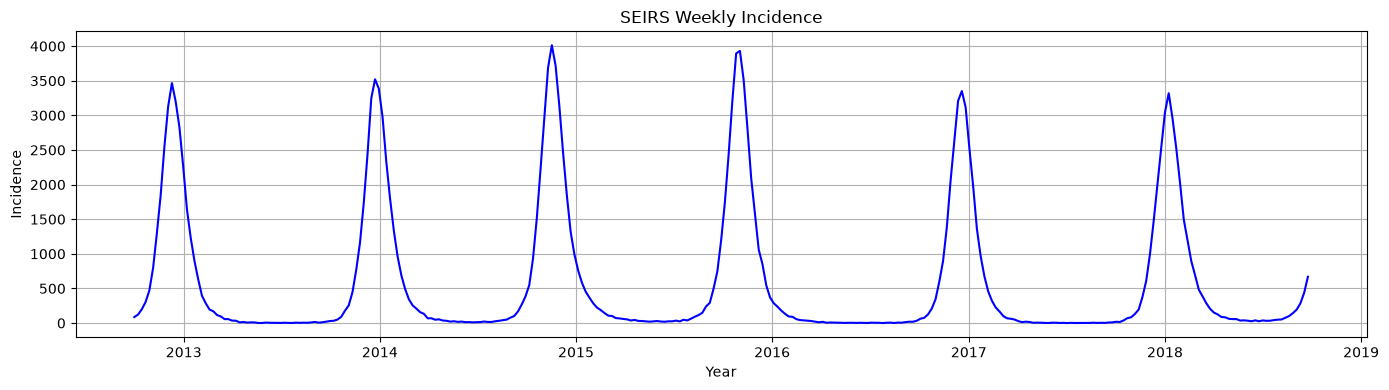

In [162]:
# --- Plot Mapping Incidence ---

fig, ax1 = plt.subplots(figsize=(14,4))

# Weekly incidence
ax1.plot(omega_fake_df['date'], omega_fake_df['positive'], label='Weekly incidence', color='blue')
ax1.set_xlabel('Year')
ax1.set_ylabel('Incidence')
ax1.grid(True)
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.title('SEIRS Weekly Incidence')
plt.tight_layout()
plt.show()

# -----

In [16]:
# --- Plot Functions (IDDinf?) ---

# Trace Plot
def trace_plot(samples, ylim=None):
    n_parms = samples.shape[1]
    
    param_names = ['log_beta', 'log_omega0', 'sigma_omega'] + [f'W_s[{i}]' for i in range(n_parms-3)]
    
    fig, axes = plt.subplots(n_parms, 1, figsize=(12, 2.5*n_parms), sharex=True)
    
    for i in range(n_parms):
        axes[i].plot(samples[:, i], color='blue', linewidth=1)
        axes[i].set_ylabel(param_names[i])
        axes[i].set_title(f'Trace plot of {param_names[i]}')
        axes[i].grid(True)
        
        if ylim is not None:
            axes[i].set_ylim(ylim[i])
    
    axes[-1].set_xlabel('Iteration')
    plt.tight_layout()
    plt.show()


# Autocorrelation Plot
def acf_plot(samples, lags = 100):
    n_parms = samples.shape[1]
    
    param_names = ['log_beta', 'log_omega0', 'log_sigma_omega'] + [f'W_s[{i}]' for i in range(n_parms-3)]

    fig, axes = plt.subplots(3, 3, figsize=(12, 9))
    axes = axes.flatten()  # flatten to index easily
    
    for i in range(n_parms):
        plot_acf(samples[:, i], ax=axes[i], lags=lags)
        axes[i].set_title(f'ACF of {param_names[i]}')
    
    # Hide unused axes (if fewer than n_rows*n_cols)
    for j in range(n_parms, len(axes)):
        axes[j].axis('off')
    
    plt.tight_layout()
    plt.show()

# -----

In [20]:
# --- Log-priors ---

def log_prior(log_omega0, log_sigma_omega, W_s):

    log_pri_log_omega0      = sp.stats.norm(-5.25, 0.25).logpdf(log_omega0)
    log_pri_log_sigma_omega = sp.stats.norm(-1, 0.5).logpdf(log_sigma_omega) 
    log_pri_W_s             = np.sum(sp.stats.norm(loc=0, scale=np.exp(log_sigma_omega)).logpdf(W_s))

    lp =  log_pri_log_omega0 + log_pri_log_sigma_omega + log_pri_W_s
    
    return lp

# -----

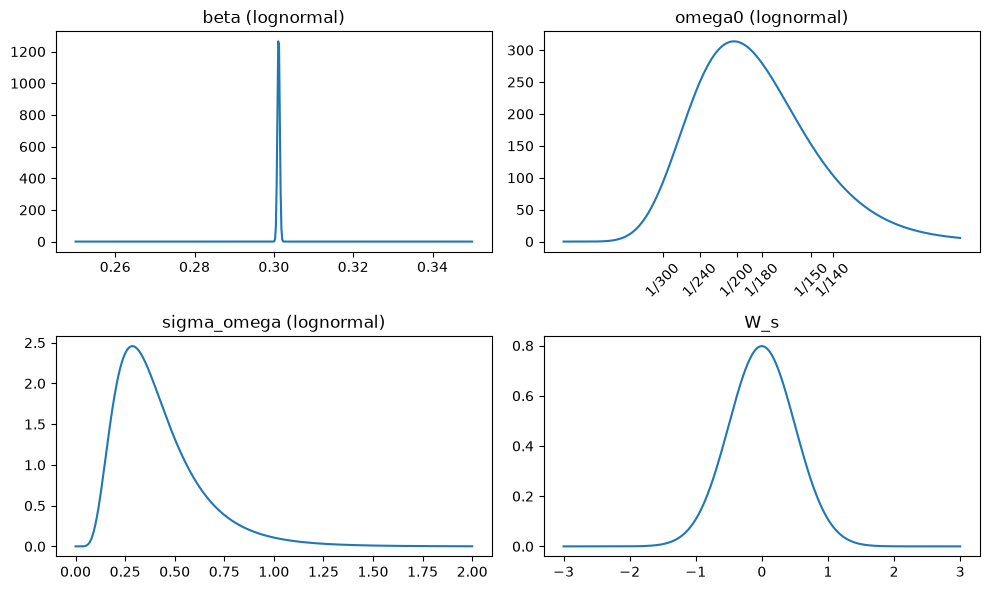

In [19]:
# --- Plot Priors ---

fig, axs = plt.subplots(2, 2, figsize=(10, 6))

# beta
x = np.linspace(0.25, 0.35, 500)
axs[0,0].plot(x, sp.stats.lognorm(s=0.001, scale=np.exp(-1.2)).pdf(x))
axs[0,0].set_title("beta (lognormal)")


# omega0
x = np.linspace(1/900, 1/100, 500)
axs[0,1].plot(x, sp.stats.lognorm(s=0.25, scale=np.exp(-5.25)).pdf(x))
axs[0,1].set_title("omega0 (lognormal)")

ticks = np.array([1/300, 1/240, 1/200, 1/180, 1/150, 1/140])
labels = [f"1/{int(1/t)}" for t in ticks]

axs[0,1].set_xticks(ticks)
axs[0,1].set_xticklabels(labels)
axs[0,1].tick_params(axis='x', rotation=45)


# sigma_omega
x = np.linspace(0, 2, 500)
axs[1,0].plot(x, sp.stats.lognorm(s = 0.5, scale = np.exp(-1)).pdf(x))
#axs[1,0].plot(x, sp.stats.norm(.4, 0.5).pdf(x))
axs[1,0].set_title("sigma_omega (lognormal)")


# W_s
x = np.linspace(-3, 3, 500)
axs[1,1].plot(x, sp.stats.norm(0, 0.5).pdf(x))
axs[1,1].set_title("W_s")

plt.tight_layout()

plt.show()

# -----

In [21]:
# --- Log-posterior ---

def log_posterior(log_beta, amp, phase, log_omega0, log_sigma_omega, W_s, sigma, data, state, rate_fn, alpha, burn_in_seasons, season_boundaries):

    total_seasons = len(season_boundaries) - 1
    
    log_omega_s = make_log_omega_s(log_omega0, W_s, total_seasons, burn_in_seasons)

    nll = nll_func_pois(log_beta, amp, phase, log_omega_s, sigma, data, state, rate_fn, alpha, burn_in_seasons, season_boundaries)
    
    log_post = -nll + log_prior(log_omega0, log_sigma_omega, W_s)
    
    return log_post

# -----

In [22]:
# --- Accept Reject Step ---

def mh_acc_rej(log_post_prop, log_post_curr, log_q_curr_prop, log_q_prop_curr):
    
    log_acc_ratio = (log_post_prop - log_post_curr + log_q_curr_prop - log_q_prop_curr)
    u = np.random.uniform()

    if np.log(u) <= log_acc_ratio:
        return True
        
    else:
        return False

# -----

In [151]:
# --- Base Covariance Matrix Scales ---

# Initial Run:
base_sd = np.array([ 
    0.005,     # log_omega0
    0.5,        # log_sigma_omega
    0.01,      # W1
    0.01,      # W2
    0.01,      # W3
    0.01,      # W4
    0.01,      # W5
    0.01      # W6
])

# -----

In [100]:
# --- MH Joint One Block ---

def adapt_mh_seirs_one(data, state, log_beta, amp, phase, log_omega0, log_sigma_omega, W_s, sigma, rate_fn, alpha, burn_in_seasons, season_boundaries, nits):

    W_s = np.array(W_s)
    curr_parms = np.hstack(([log_beta, log_omega0, log_sigma_omega], W_s)) 

    d = len(curr_parms)
    
    samples = np.zeros((nits, d))
    accept_flags = np.zeros(nits)    # vector of accept reject

    
    # Initialise log-posterior    
    log_post_curr = log_posterior(curr_parms[0], amp, phase, curr_parms[1], curr_parms[2], curr_parms[3:], sigma, data, state, rate_fn, alpha, burn_in_seasons, season_boundaries)

    
    # MCMC Loop
    for i in range(nits):
        
        prop = curr_parms.copy()

        
# ----- One Block Update:
        eta  = 0.05    # mixture distribution weighting

        base_cov = np.diag(base_sd**2)/d


        # Proposal Step
        if i <= 5000:
            prop = curr_parms + np.random.multivariate_normal(np.zeros(d), base_cov)    # mvn needs cov matrix

        else:            
            sigma_n = np.cov(samples[:i].T, ddof = 1)    # empirical covariance of chain up to iteration i
            adapt_cov = (2 ** 2 / d) * sigma_n    # adaptive covariance form -> try smaller 2.38
            
            # Mixture proposal
            if np.random.rand() < eta:
                prop_cov = base_cov
                
            else:
                prop_cov = adapt_cov

            
            prop = curr_parms + np.random.multivariate_normal(np.zeros(d), prop_cov)

        
# ----- Accept Reject Step:
        log_post_prop = log_posterior(prop[0], amp, phase, prop[1], prop[2], prop[3:], sigma, data, state, rate_fn, alpha, burn_in_seasons, season_boundaries)    # log-posterior at proposed values

        acc_rej_bool = mh_acc_rej(log_post_prop, log_post_curr, 0, 0)    # determine accept or reject

        if acc_rej_bool:
            curr_parms = prop
            log_post_curr = log_post_prop
            accept_flags[i] = 1
            

        # Save samples after updates:
        samples[i, :] = curr_parms
            
    return samples, accept_flags

# -----

In [101]:
# --- MH Joint One Block + Diagnostics ---

def adapt_mh_seirs_one(data, state, log_beta, amp, phase, log_omega0, log_sigma_omega, W_s, sigma, rate_fn, alpha, burn_in_seasons, season_boundaries, nits):

    W_s = np.array(W_s)
    curr_parms = np.hstack(([log_omega0, log_sigma_omega], W_s))

    d = len(curr_parms)

    samples = np.zeros((nits, d))
    accept_flags = np.zeros(nits)

    # Diagnostics
    log_post_trace = np.zeros(nits)                       # Log-posterior of the current accepted parameters at each iteration
    log_post_prop_trace = np.zeros(nits)                  # Log-posterior of the proposed parameters at each iteration
    log_accept_ratio_trace = np.zeros(nits)               # Log acceptance ratio for each proposal
    proposal_type_trace = np.empty(nits, dtype=object)    # Records whether each proposal used the base or adaptive covariance

    # Initialise log-posterior
    log_post_curr = log_posterior(log_beta, amp, phase, curr_parms[0], curr_parms[1], curr_parms[2:], sigma, data, state, rate_fn, alpha, burn_in_seasons, season_boundaries)

    # MCMC Loop
    for i in range(nits):

        prop = curr_parms.copy()

# ----- One Block Update:
        eta = 0.05    # mixture distribution weighting

        base_cov = np.diag(base_sd**2)/d
        #base_cov = np.diag((2.38**2 / d) * base_var)

        # Proposal Step
        if i <= 5000:

            prop = curr_parms + np.random.multivariate_normal(np.zeros(d), base_cov)
            proposal_type_trace[i] = "base"

        else:
            sigma_n = np.cov(samples[:i].T, ddof=1)
            adapt_cov = ((2.38/2)**2 / d) * sigma_n

            # Mixture proposal
            if np.random.rand() < eta:
                prop_cov = base_cov
                proposal_type_trace[i] = "base"
            else:
                prop_cov = adapt_cov
                proposal_type_trace[i] = "adaptive"

            prop = curr_parms + np.random.multivariate_normal(np.zeros(d), prop_cov)

        
# ----- Accept / Reject Step:
        log_post_prop = log_posterior(log_beta, amp, phase, prop[0], prop[1], prop[2:], sigma, data, state, rate_fn, alpha, burn_in_seasons, season_boundaries)    # log-posterior at proposed values

        log_acc_ratio = log_post_prop - log_post_curr

        if not np.isfinite(log_post_prop):
            log_acc_ratio = -np.inf

        log_accept_ratio_trace[i] = log_acc_ratio
        log_post_prop_trace[i] = log_post_prop

        acc_rej_bool = mh_acc_rej(log_post_prop, log_post_curr, 0, 0)

        if acc_rej_bool:
            curr_parms = prop
            log_post_curr = log_post_prop
            accept_flags[i] = 1

        # Save current state after update
        samples[i, :] = curr_parms
        log_post_trace[i] = log_post_curr

    # Return samples and diagnostics
    diagnostics = {"log_posterior": log_post_trace,
                   "proposed_log_posterior": log_post_prop_trace,
                   "log_acceptance_ratio": log_accept_ratio_trace,
                   "proposal_type": proposal_type_trace}

    return samples, accept_flags, diagnostics

# -----


In [103]:
# --- MCMC Runs ---

# Initial parameter values - slightly adjusted from previous values to try reduce burn-in
np.random.seed(45)

init_log_beta        = np.log(0.3)
init_log_omega0      = -5.25
init_log_sigma_omega = -0.5
init_W_s             = np.zeros(6)

nits = 100000

samples, accept_vec, diag = adapt_mh_seirs_one(omega_fake_df, init,
                                         init_log_beta, amp, phase, init_log_omega0, init_log_sigma_omega, init_W_s,
                                         sigma, my_rate, alpha, burn_in_seasons, season_bounds, nits)

print("-----")
print(f"Acceptance Rate (All): {np.mean(accept_vec):.3f}")
print(f"Acceptance Rate (Burn-In): {np.mean(accept_vec[7500:]):.3f}")
print("-----")

# -----

-----
Acceptance Rate (All): 0.023
Acceptance Rate (Burn-In): 0.022
-----


In [949]:
#np.save("best-run-250k.npy", samples)

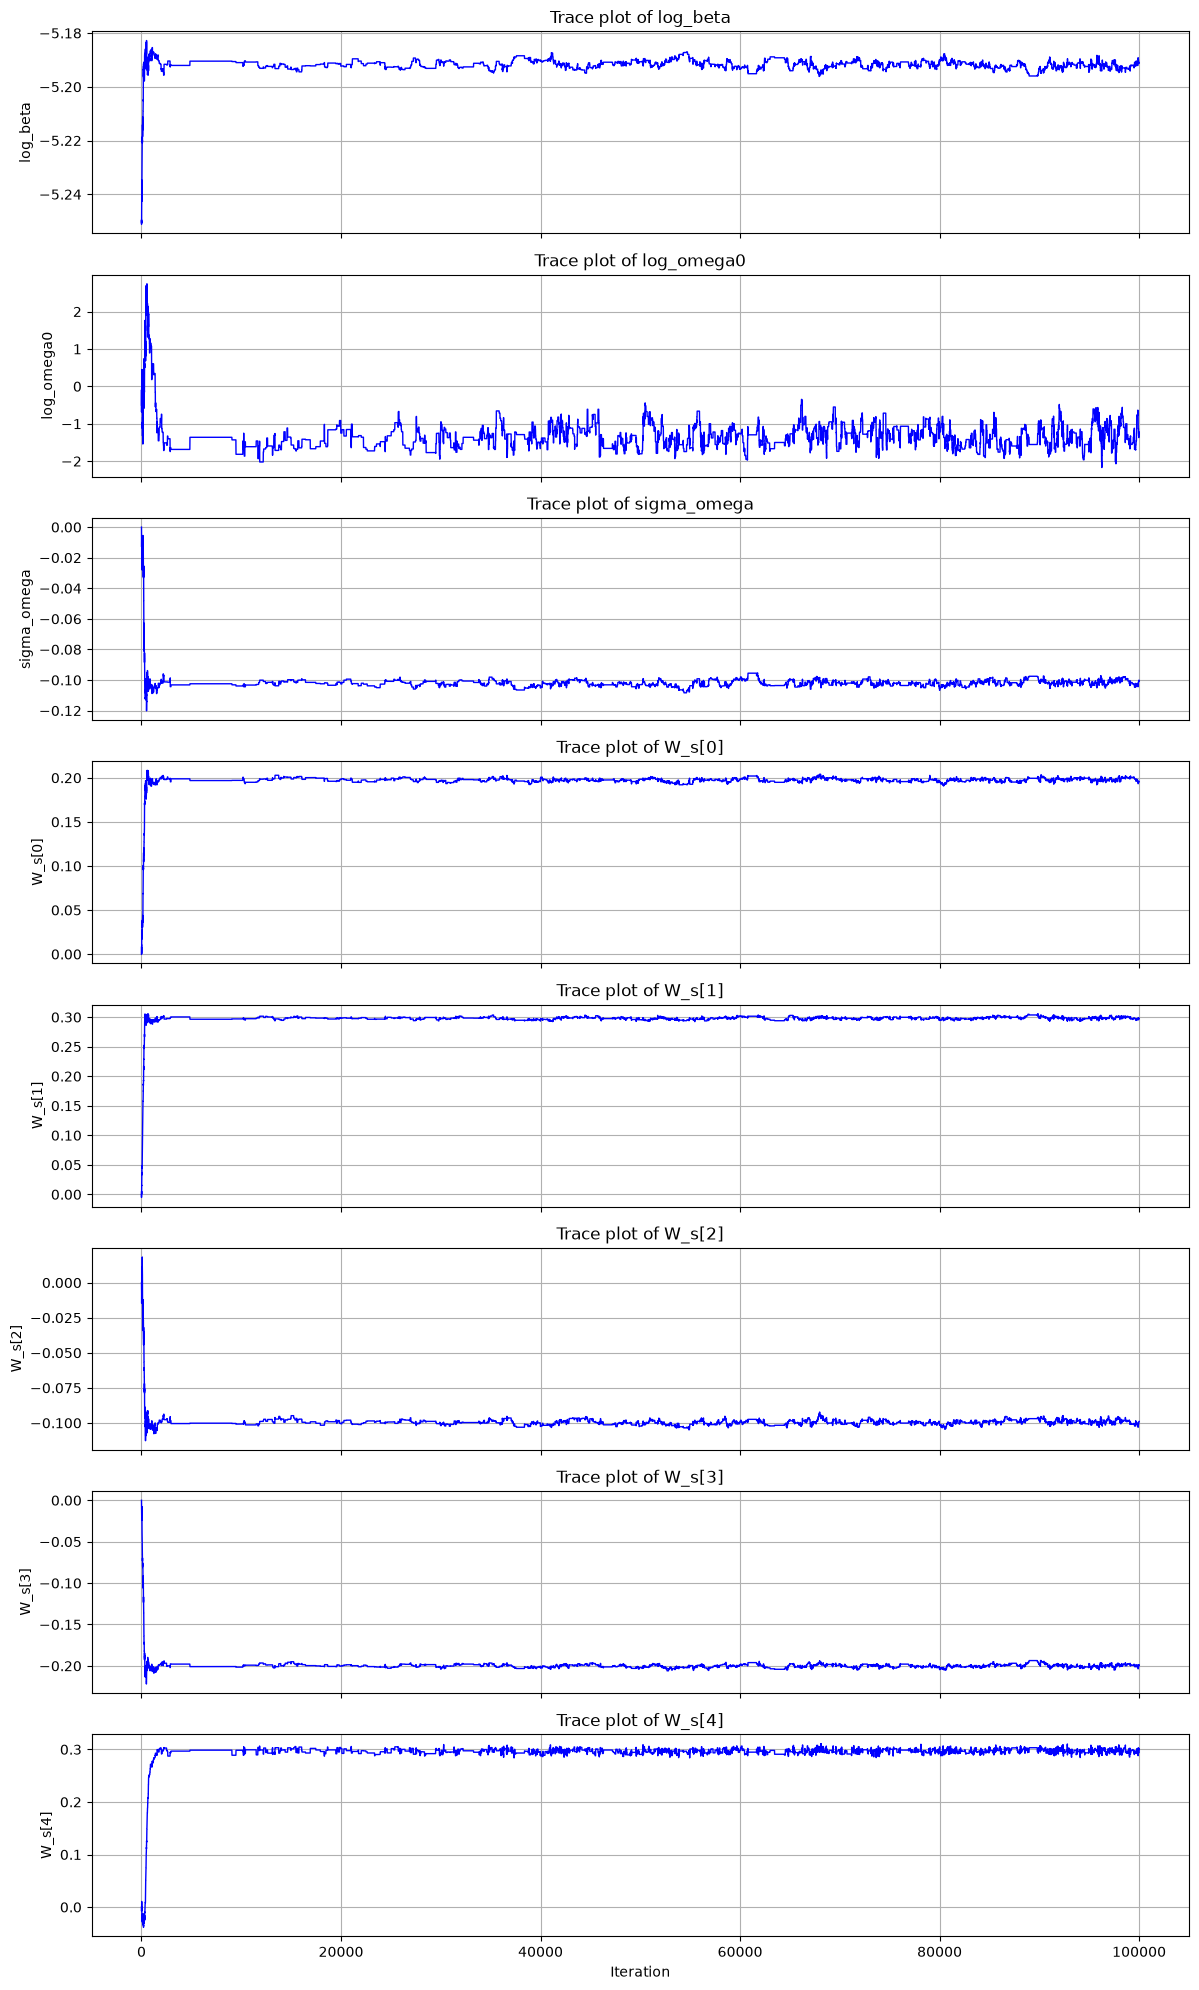

In [144]:
# --- Plots ---

trace_plot(samples, None)

# -----

Acceptance Rate: 0.027


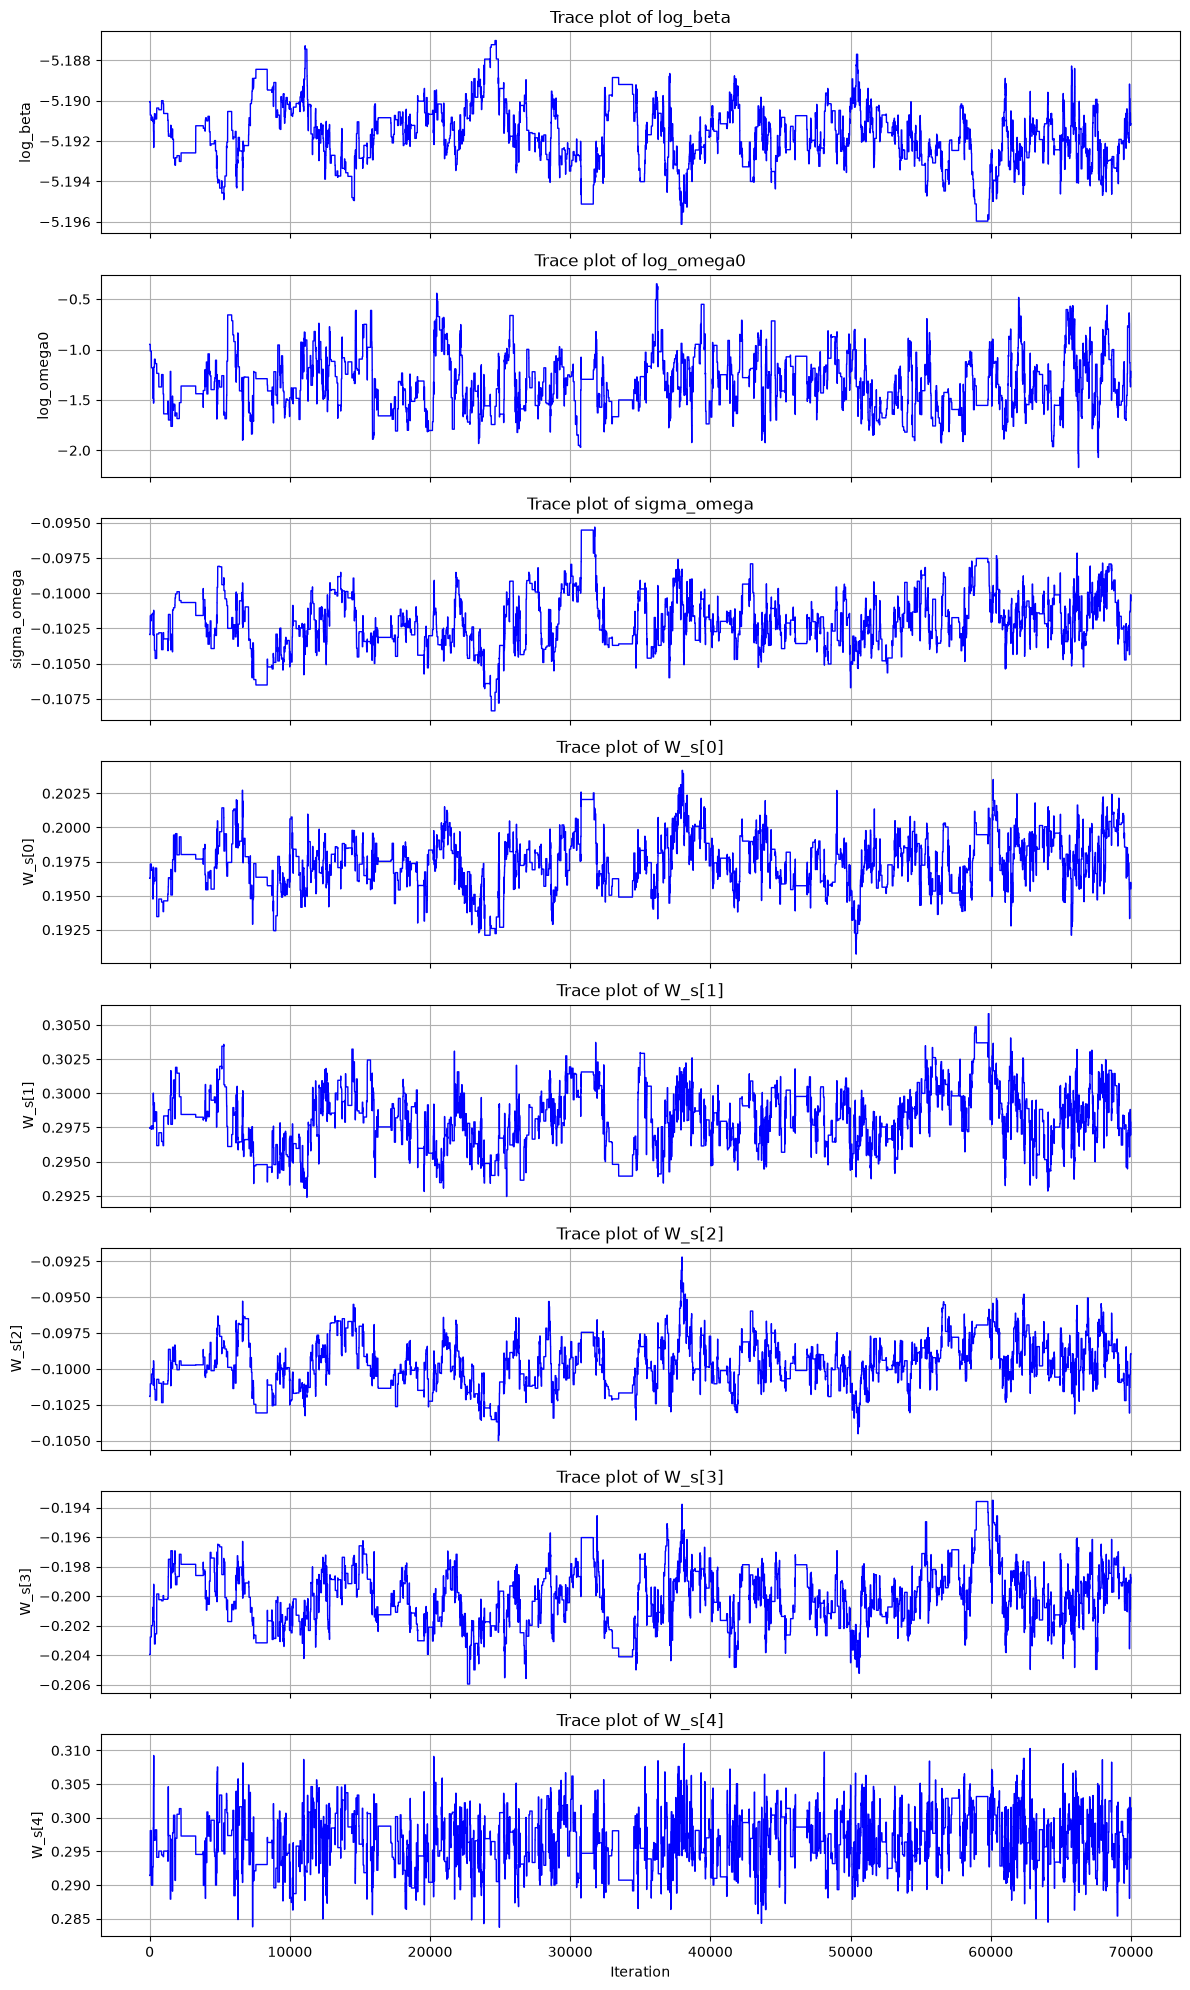

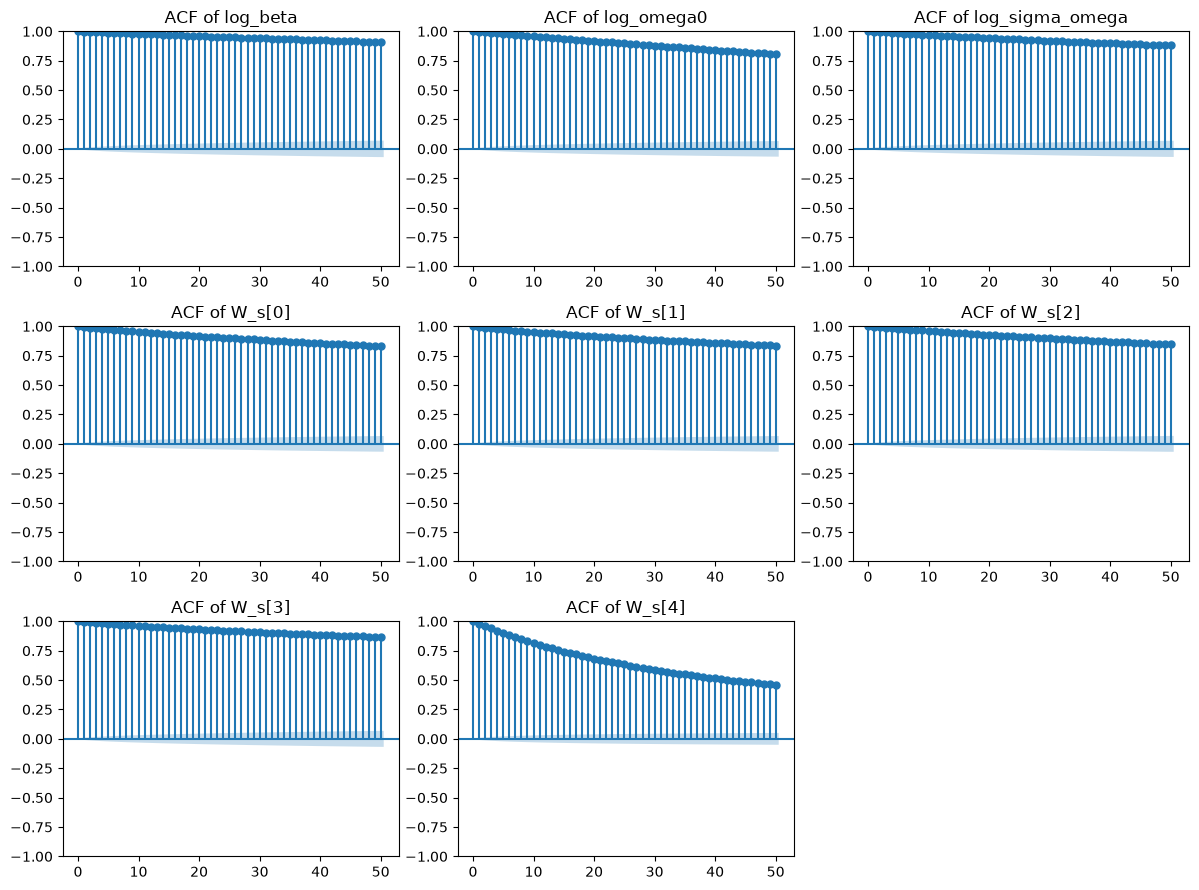

In [145]:
# --- Plots ---

burn_itn = 30000
#burn_itn = 700

samples_burn = samples[burn_itn:]
print(f"Acceptance Rate: {np.mean(accept_vec[burn_itn:]):.3f}")

trace_plot(samples_burn, None)

acf_plot(samples_burn, lags=50)

# -----

In [146]:
# --- True vs Median Parameters ---

n_parms = samples_burn.shape[1]

med_vals  = np.median(samples_burn, axis=0)

true_vals = [true_log_omega0, true_log_sigma_omega] + list(true_W_s)
param_names = ['log_beta', 'omega0', 'sigma_omega'] + [f'W_s[{i}]' for i in range(len(true_W_s))]


print("-----")
print("True parameter values:")

for name, val, med in zip(param_names, true_vals, med_vals):
    print(f"{name}: {val:.4f}, {med:.4f}")
print("-----")

# -----

-----
True parameter values:
log_beta: -5.1930, -5.1917
omega0: -0.6931, -1.3545
sigma_omega: -0.1000, -0.1022
W_s[0]: 0.2000, 0.1975
W_s[1]: 0.3000, 0.2982
W_s[2]: -0.1000, -0.0997
W_s[3]: -0.2000, -0.2001
W_s[4]: 0.3000, 0.2965
-----


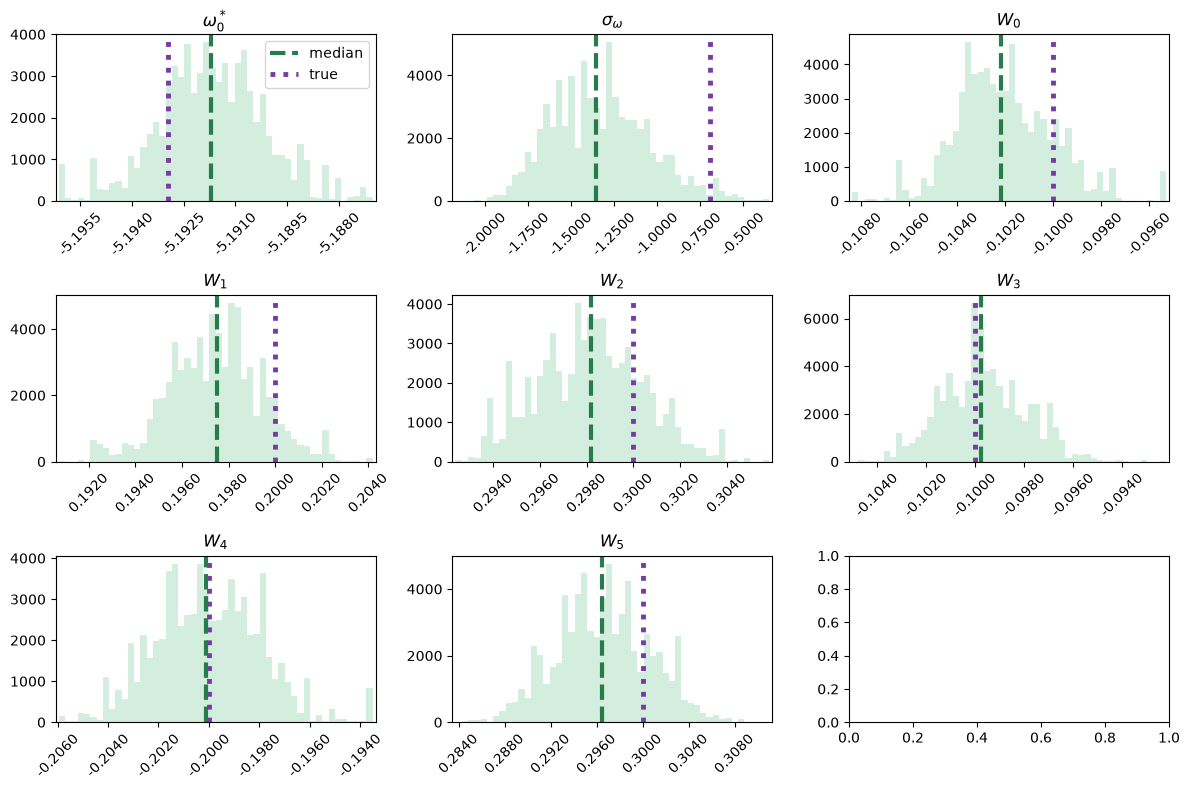

In [147]:
# --- Posterior Predictive Check ---

# Parameter Names (LaTeX Symbols)
param_names = [
    r'$\omega_0^*$',
    r'$\sigma_\omega$'
] + [rf'$W_{{{i}}}$' for i in range(6)]

true_vals = [true_log_omega0, true_log_sigma_omega] + true_W_s


fig, axes = plt.subplots(3, 3, figsize=(12, 8))
axes = axes.flatten()

for i in range(8):
    samples_i = samples_burn[:, i]
    true_val = true_vals[i]

    min_val, max_val = samples_i.min(), samples_i.max()
    
    min_val = min(min_val, true_val)
    max_val = max(max_val, true_val)

    # Padding
    padding = 0.01 * (max_val - min_val)
    min_val -= padding
    max_val += padding
    
    
    # Histogram
    axes[i].hist(samples_i, bins=50, color='#A8DCBE', alpha=0.5)

    # Median Lines
    med_val = med_vals[i]
    axes[i].axvline(med_val, linestyle='--', color='#267D4A', linewidth=3, label='median', alpha = 1)

    # Include True Values (except sigma_omega - when W_s = 0)
    axes[i].axvline(true_val, linestyle=':', color='#7A3AA3', linewidth=3.5, label='true', alpha = 1)

    # Titles / Labels
    axes[i].set_title(param_names[i])
    axes[i].set_xlim(min_val, max_val)
    axes[i].tick_params(axis='x', rotation=45)
    
            
    # Cleaner Ticks# Continuous parameters - decimals
    axes[i].xaxis.set_major_locator(mticker.MaxNLocator(8))
    axes[i].xaxis.set_major_formatter(mticker.FormatStrFormatter('%.4f'))
        

# Hide any extra axes
for j in range(9, len(axes)):
    axes[j].axis('off')

# Only show legend on first plot
axes[0].legend()

plt.tight_layout()
plt.show()

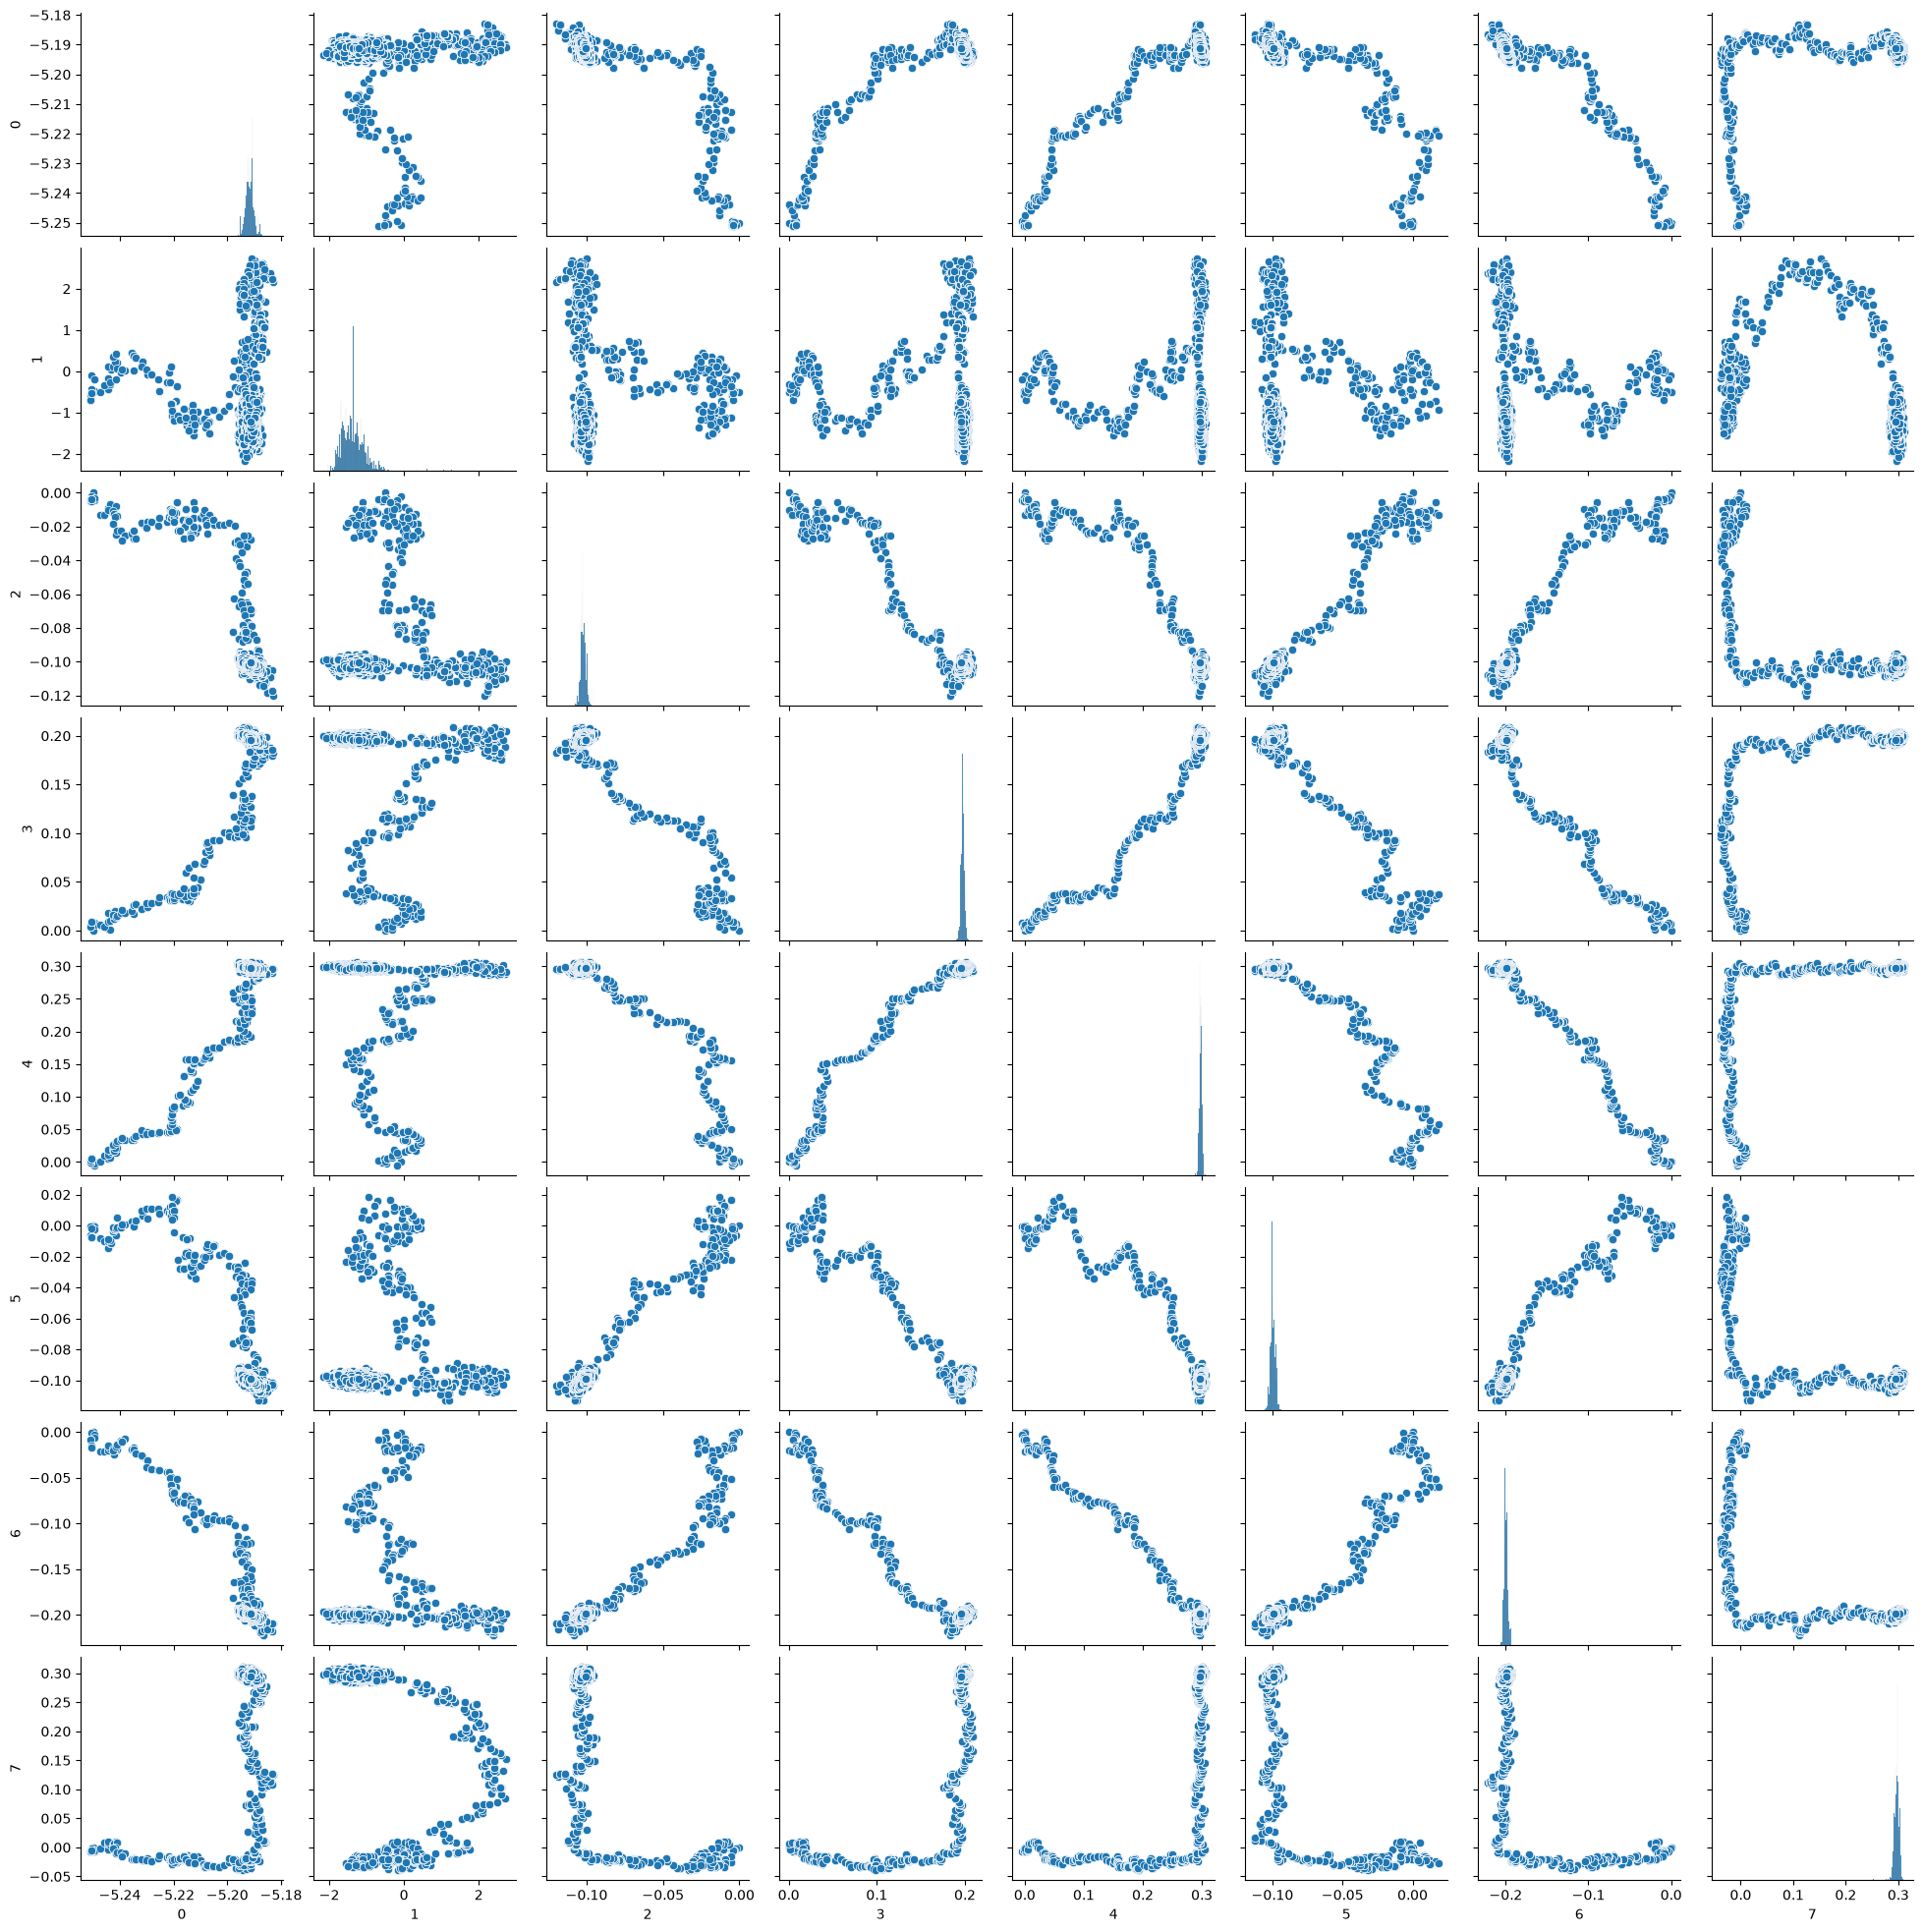

In [125]:
sns.pairplot(pd.DataFrame(samples))
plt.show()

In [152]:
# --- Compare base_sd settings with adaptive proposal SDs ---

d = samples.shape[1]
sample_cov = np.cov(samples_burn.T, ddof=1)

base_cov = np.diag(base_sd**2) / d
adapt_cov = ((2.38 / 4)**2 / d) * sample_cov

parameter_names = (
    ["log_omega0", "log_sigma_omega"]
    + [f"W_{j+1}" for j in range(d - 2)]
)

print(f"{'Parameter':<18} {'Current base_sd':>16} "
      f"{'Actual Base SD':>16} {'Adaptive SD':>14} "
      f"{'Base/Adapt':>12}")

for i, name in enumerate(parameter_names):
    actual_base_sd = np.sqrt(base_cov[i, i])
    adaptive_sd = np.sqrt(adapt_cov[i, i])
    ratio = actual_base_sd / adaptive_sd

    print(f"{name:<18} {base_sd[i]:>16.6f} "
          f"{actual_base_sd:>16.6f} {adaptive_sd:>14.6f} "
          f"{ratio:>12.2f}")


Parameter           Current base_sd   Actual Base SD    Adaptive SD   Base/Adapt
log_omega0                 0.005000         0.001768       0.000332         5.33
log_sigma_omega            0.500000         0.176777       0.059379         2.98
W_1                        0.010000         0.003536       0.000435         8.12
W_2                        0.010000         0.003536       0.000422         8.38
W_3                        0.010000         0.003536       0.000479         7.39
W_4                        0.010000         0.003536       0.000363         9.74
W_5                        0.010000         0.003536       0.000444         7.97
W_6                        0.010000         0.003536       0.000858         4.12


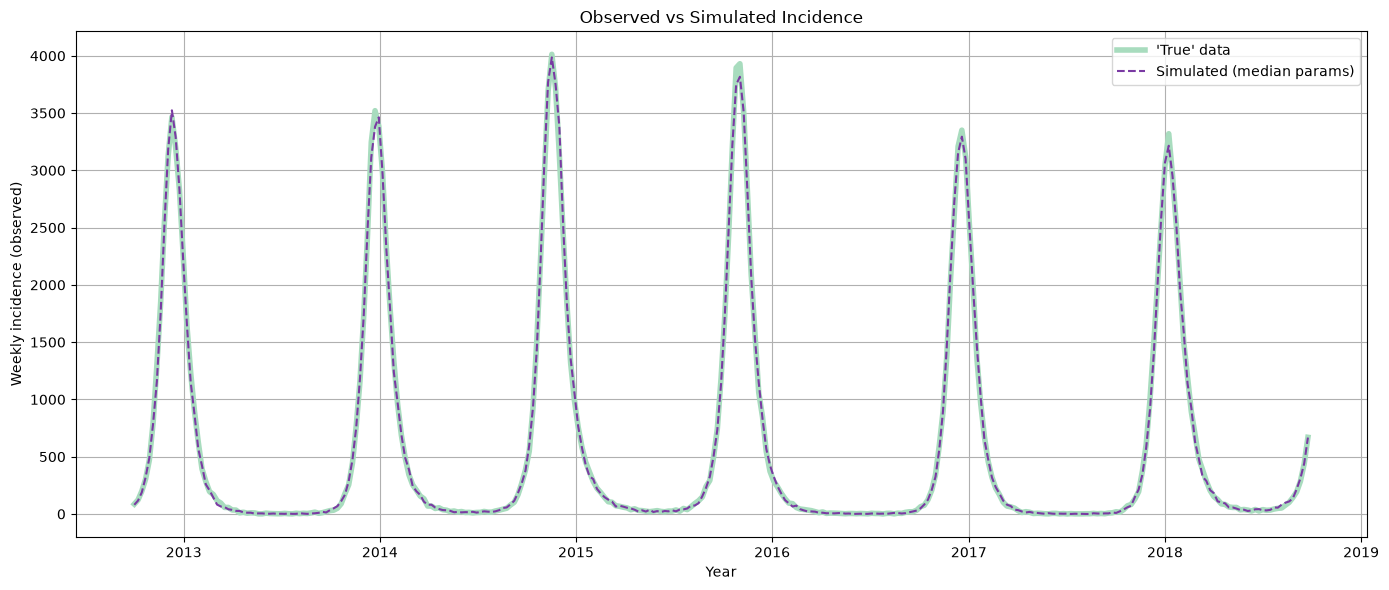

In [163]:
# --- Trajectories ---

med_omega0 = med_vals[0]
med_log_sigma_omega = med_vals[1]
med_ws = med_vals[2:]

med_log_omega_s = make_log_omega_s(med_omega0, med_ws, total_seasons, burn_in_seasons)

med_df = sim_seirs(init, init_log_beta, amp, phase, med_log_omega_s, sigma, my_rate, burn_in_seasons, season_bounds)
med_df['positive'] = np.random.poisson(med_df["incidence"] * alpha)    # add observation noise


med_df["date"]        = omega_fake_df["date"]


# --- Plot ---
fig, ax = plt.subplots(figsize=(14,6))

# True data
ax.plot(
    omega_fake_df["date"],
    omega_fake_df["positive"],
    label="'True' data",
    color='#A8DCBE',
    linewidth=4
)

# Simulated data
ax.plot(
    med_df["date"],
    med_df["positive"],
    label="Simulated (median params)",
    color='#7A3AA3',
    linestyle="--",
    alpha = 1
)

# Formatting
ax.set_xlabel("Year")
ax.set_ylabel("Weekly incidence (observed)")
ax.grid(True)

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

ax.legend()

plt.title("Observed vs Simulated Incidence")
plt.tight_layout()
plt.show()
start_date = pd.Timestamp.fromisocalendar(2012, 40, 1) 


---
# Fitting to Data

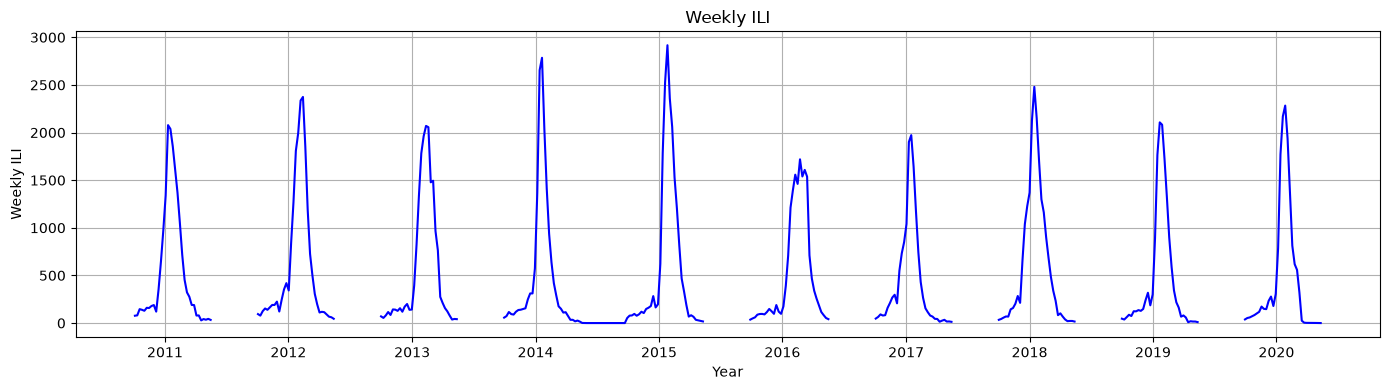

In [164]:
# --- Plot Mapping Incidence ---

fig, ax = plt.subplots(figsize=(14,4))

# Weekly incidence
ax.plot(df['week_start'], df['positive'], label='Weekly ILI', color='blue')
ax.set_xlabel('Year')
ax.set_ylabel('Weekly ILI')
ax.grid(True)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.title('Weekly ILI')
plt.tight_layout()
plt.show()

# -----

In [165]:
# Simulation settings
np.random.seed(120)

# Fixed Values
init          = [44999999, 0, 1, 0]
sigma         = 1/2
gamma         = 1/5

alpha         = 0.001

amp = -0.2
phase = -2.2

burn_in_seasons = 20
season_bounds = get_season_boundaries(2010, 3, burn_in_seasons)
total_seasons = len(season_bounds) - 1

my_rate          = set_rate(sigma, gamma)


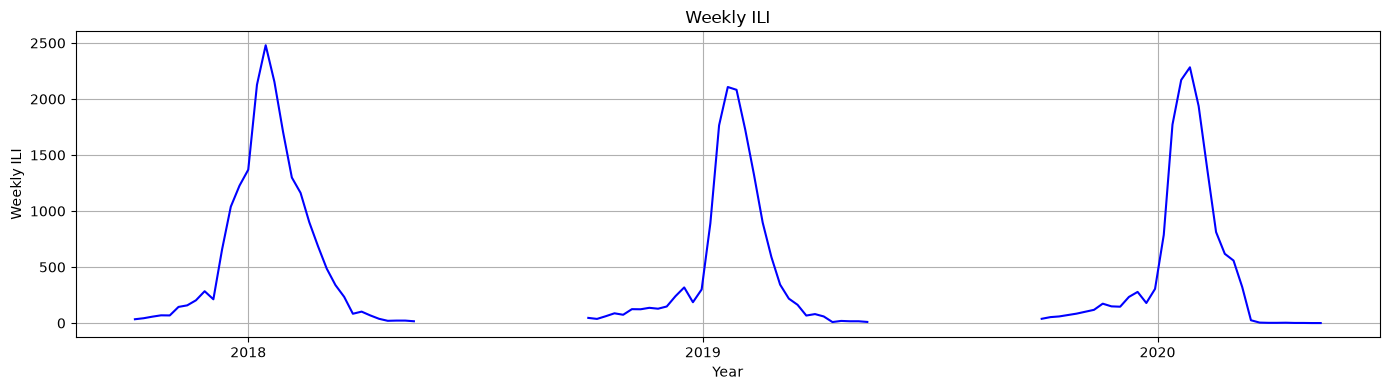

In [166]:
last_3_seasons = sorted(df["season"].dropna().unique())[-3:]

df_last3 = (
    df[df["season"].isin(last_3_seasons)]
    .copy()
    .reset_index(drop=True)
)

# --- Plot Mapping Incidence ---

fig, ax = plt.subplots(figsize=(14,4))

# Weekly incidence
ax.plot(df_last3['week_start'], df_last3['positive'], label='Weekly ILI', color='blue')
ax.set_xlabel('Year')
ax.set_ylabel('Weekly ILI')
ax.grid(True)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.title('Weekly ILI')
plt.tight_layout()
plt.show()

# -----

In [ ]:
- shrinking 2.38 - algorithm for estimating 2.38
- fix beta (1st) !!!!
- HMC - GemLib

In [167]:
# --- MCMC Runs ---

# Initial parameter values - slightly adjusted from previous values to try reduce burn-in
np.random.seed(45)

init_log_beta        = np.log(0.3)
init_log_omega0      = np.log(1/300)
init_log_sigma_omega = np.log(0.5)
init_W_s             = np.zeros(3)

base_sd = np.array([
    0.1,  # omega0
    0.5,  # sigma_omega
    *([0.1] * 3)  # W_s
])

nits = 25000

samples_fit, accept_vec_fit, diag_fit = adapt_mh_seirs_one(df_last3, init,
                                         init_log_beta, amp, phase, init_log_omega0, init_log_sigma_omega, init_W_s,
                                         sigma, my_rate, alpha, burn_in_seasons, season_bounds, nits)

print("-----")
print(f"Acceptance Rate (All): {np.mean(accept_vec):.3f}")
print(f"Acceptance Rate (Burn-In): {np.mean(accept_vec[7500:]):.3f}")
print("-----")

# -----

-----
Acceptance Rate (All): 0.023
Acceptance Rate (Burn-In): 0.022
-----


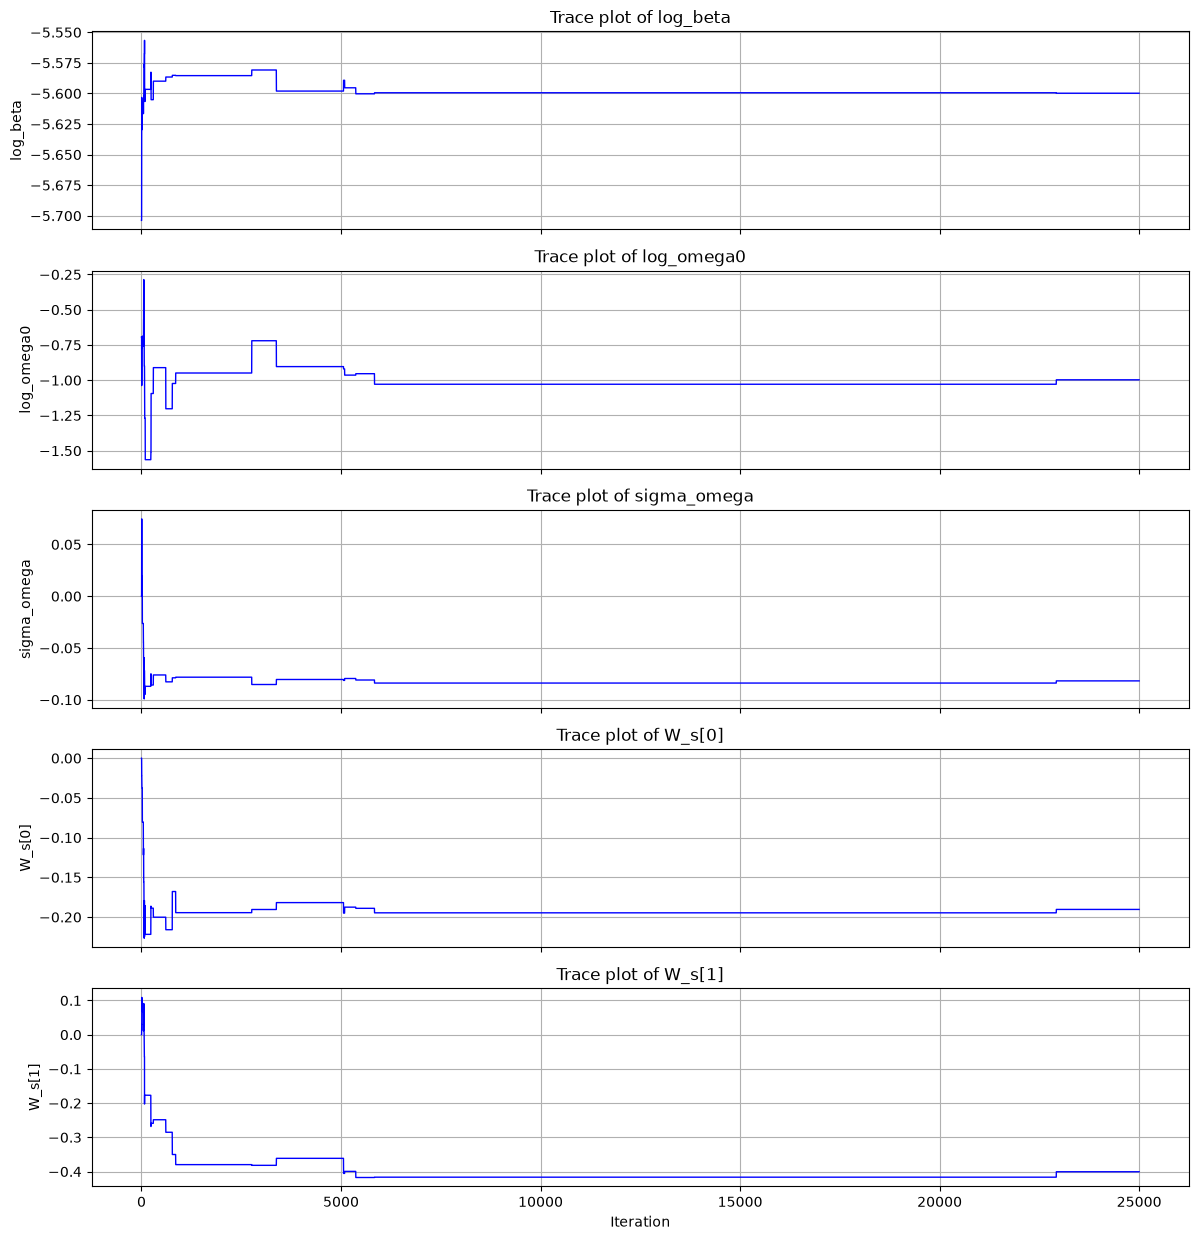

In [169]:
# --- Plots ---

trace_plot(samples_fit, None)

# -----

In [170]:
# --- True vs Median Parameters ---

samples_burn = samples_fit[:5000]

n_parms = samples_burn.shape[1]

med_vals  = np.median(samples_burn, axis=0)

param_names = ['omega0', 'sigma_omega'] + [f'W_s[{i}]' for i in range(len(init_W_s))]


print("-----")
print("Parameter values:")

for name, med in zip(param_names, med_vals):
    print(f"{name}: {med:.4f}")

print("-----")

# -----

-----
Parameter values:
omega0: -5.5854
sigma_omega: -0.9107
W_s[0]: -0.0804
W_s[1]: -0.1944
W_s[2]: -0.3797
-----


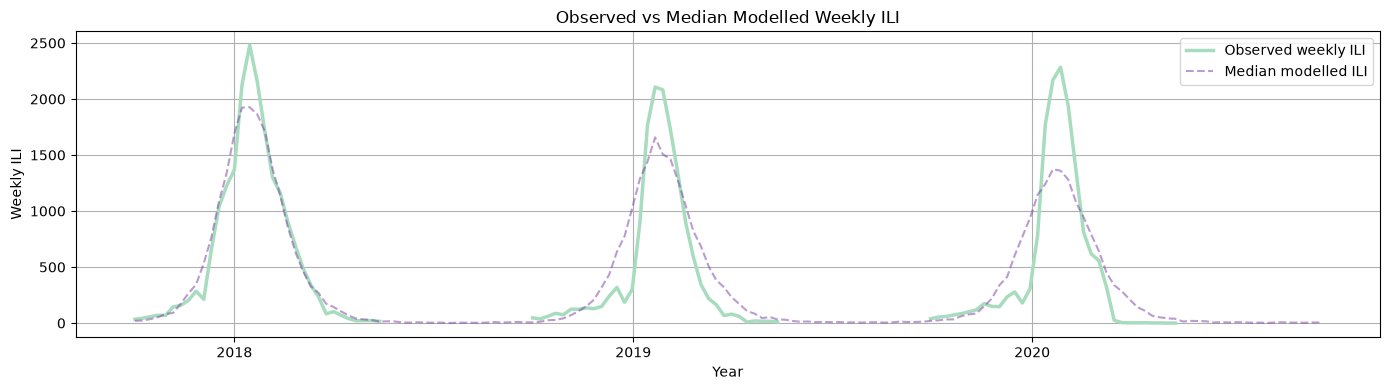

In [172]:
# --- Trajectories ---

med_omega0 = med_vals[0]
med_log_sigma_omega = med_vals[1]
med_ws = med_vals[2:]

med_log_omega_s = make_log_omega_s(med_omega0, med_ws, total_seasons, burn_in_seasons)

med_df = sim_seirs(init, init_log_beta, amp, phase, med_log_omega_s, sigma, my_rate, burn_in_seasons, season_bounds)
med_df['positive'] = np.random.poisson(med_df["incidence"] * alpha)    # add observation noise

# --- Plot Observed and Median Modelled Incidence ---

fig, ax = plt.subplots(figsize=(14, 4))

# Observed weekly ILI
ax.plot(
    df_last3['week_start'],
    df_last3['positive'],
    label='Observed weekly ILI',
    color='#A8DCBE',
    linewidth=2.5
)

# Median modelled incidence
ax.plot(
    df_last3['week_start'].iloc[:len(med_df)],
    med_df['positive'],
    label='Median modelled ILI',
    color='#7A3AA3',
    linestyle="--",
    alpha = 0.5
)

ax.set_xlabel('Year')
ax.set_ylabel('Weekly ILI')
ax.grid(True)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.legend()

plt.title('Observed vs Median Modelled Weekly ILI')
plt.tight_layout()
plt.show()

In [168]:
base_mask = diag["proposal_type"] == "base"
adaptive_mask = diag["proposal_type"] == "adaptive"

base_rate = np.mean(accept_vec[base_mask])
adaptive_rate = np.mean(accept_vec[adaptive_mask])

print(f"Base proposal acceptance rate: {base_rate:.3f}")
print(f"Adaptive proposal acceptance rate: {adaptive_rate:.3f}")

Base proposal acceptance rate: 0.034
Adaptive proposal acceptance rate: 0.022


In [1169]:
# --- Compare fixed and adaptive proposal standard deviations ---

d = samples.shape[1]

base_cov = np.diag(base_sd**2)/d
sample_cov = np.cov(samples.T, ddof=1)
adapt_cov = ((2.38/2)**2 / d) * sample_cov

parameter_names = (
    ["log_beta", "log_omega0", "log_sigma_omega"]
    + [f"W_{j+1}" for j in range(d - 3)]
)

print(f"{'Parameter':<15} {'Base SD':>12} {'Adaptive SD':>15}")

for j, name in enumerate(parameter_names):
    base_sd_j = np.sqrt(base_cov[j, j])
    adapt_sd_j = np.sqrt(max(adapt_cov[j, j], 0))

    print(f"{name:<15} {base_sd_j:>12.5f} {adapt_sd_j:>15.5f}")

Parameter            Base SD     Adaptive SD
log_beta             0.00000         0.00000
log_omega0           0.04082         0.00193
log_sigma_omega      0.20412         0.03082
W_1                  0.04082         0.00107
W_2                  0.04082         0.00267
W_3                  0.04082         0.01236


In [1170]:
cov_matrix = np.cov(samples, rowvar=False)

std_devs = np.sqrt(np.diag(cov_matrix))

corr_matrix = cov_matrix / np.outer(std_devs, std_devs)

print(np.round(corr_matrix, 3))

[[ 1.    -0.154  0.372  0.73   0.869  0.746]
 [-0.154  1.    -0.015 -0.016  0.046 -0.005]
 [ 0.372 -0.015  1.    -0.006  0.546 -0.281]
 [ 0.73  -0.016 -0.006  1.     0.612  0.793]
 [ 0.869  0.046  0.546  0.612  1.     0.509]
 [ 0.746 -0.005 -0.281  0.793  0.509  1.   ]]


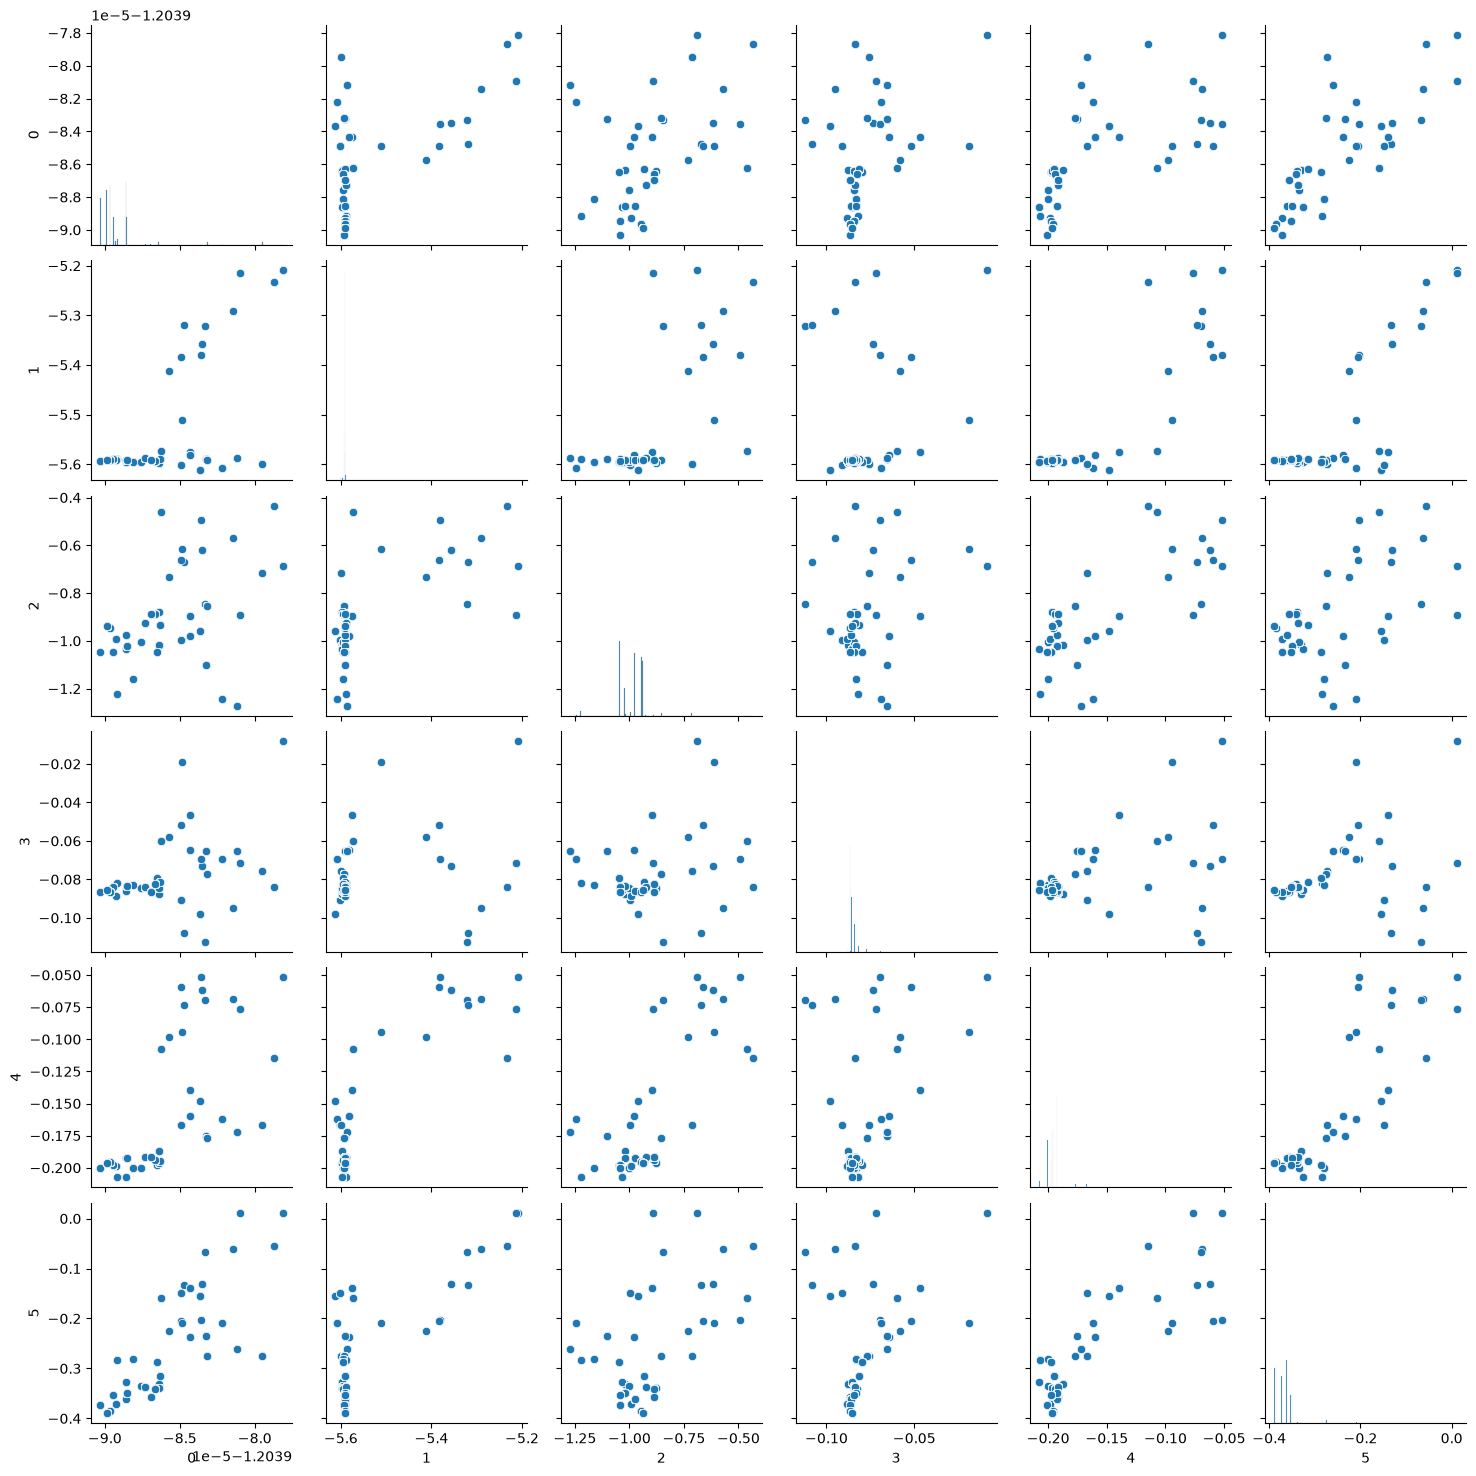

In [1171]:
sns.pairplot(pd.DataFrame(samples))
plt.show()

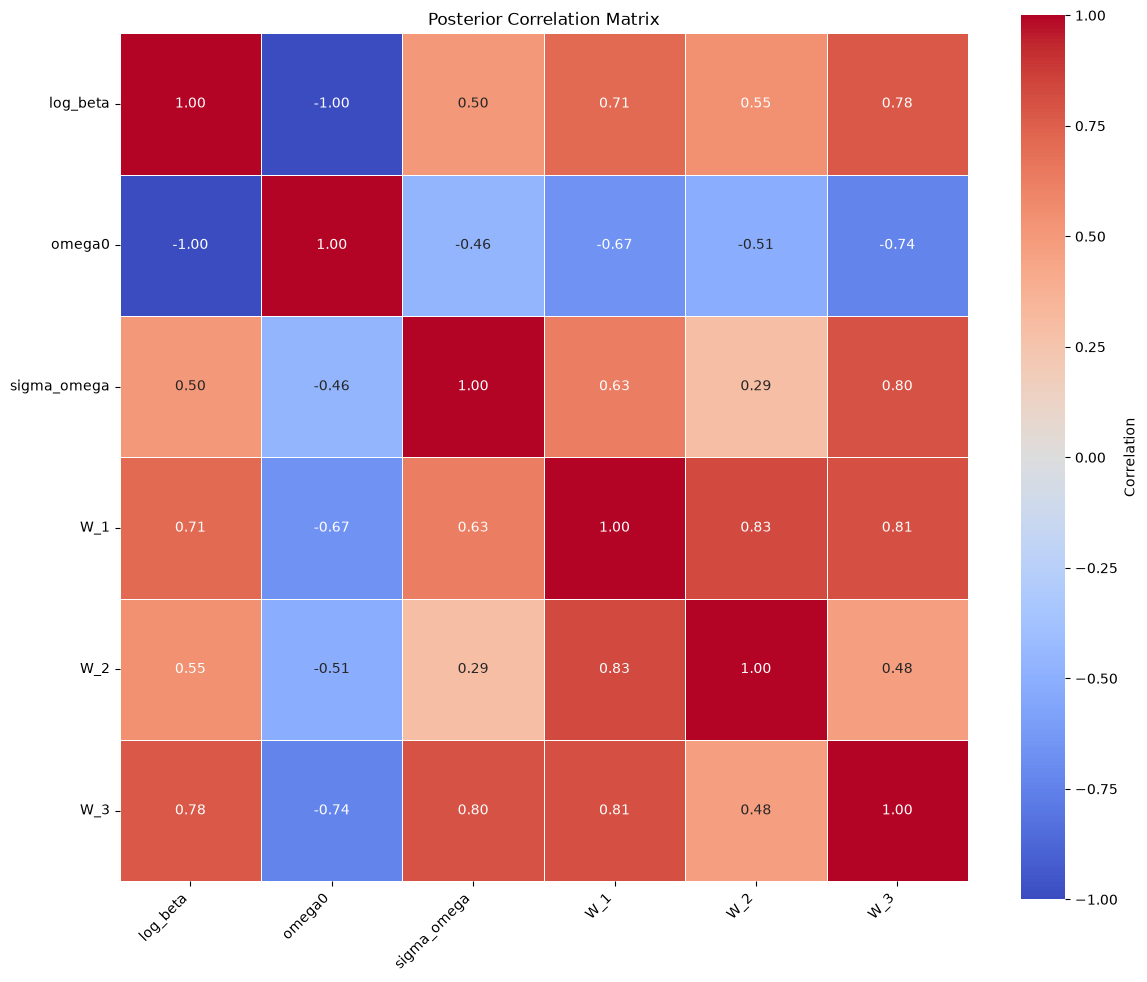

In [1107]:
import seaborn as sns

# Calculate correlation matrix
cov_matrix = np.cov(samples, rowvar=False)
std_devs = np.sqrt(np.diag(cov_matrix))
corr_matrix = cov_matrix / np.outer(std_devs, std_devs)

# Actual parameter names
param_names = [
    "log_beta",
    "omega0",
    "sigma_omega"
] + [f"W_{s+1}" for s in range(samples.shape[1] - 3)]

# Plot correlation heatmap
plt.figure(figsize=(12, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=param_names,
    yticklabels=param_names,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Correlation"}
)

plt.title("Posterior Correlation Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [1075]:

import numpy as np

# Covariance matrix estimated from the MCMC samples
cov_matrix = np.cov(samples, rowvar=False)

# Eigenvalues of the covariance matrix
eigenvalues = np.linalg.eigvalsh(cov_matrix)

print("Eigenvalues:")
print(eigenvalues)

print("\nSmallest eigenvalue:", eigenvalues.min())
print("Largest eigenvalue:", eigenvalues.max())

# Condition number
if eigenvalues.min() > 0:
    condition_number = eigenvalues.max() / eigenvalues.min()
    print("Condition number:", condition_number)
else:
    print("Covariance matrix is singular or numerically problematic.")


Eigenvalues:
[2.37462813e-06 4.49360326e-06 5.38375785e-05 1.99830216e-03
 5.01593178e-02 4.73793976e+00]

Smallest eigenvalue: 2.3746281301598142e-06
Largest eigenvalue: 4.737939758843078
Condition number: 1995234.4110924902


In [1076]:

# Correlation matrix
std_devs = np.sqrt(np.diag(cov_matrix))
corr_matrix = cov_matrix / np.outer(std_devs, std_devs)

# Eigenvalues of the correlation matrix
corr_eigenvalues = np.linalg.eigvalsh(corr_matrix)

print("Correlation matrix eigenvalues:")
print(corr_eigenvalues)

print("\nSmallest correlation eigenvalue:", corr_eigenvalues.min())
print("Largest correlation eigenvalue:", corr_eigenvalues.max())

if corr_eigenvalues.min() > 0:
    corr_condition = corr_eigenvalues.max() / corr_eigenvalues.min()
    print("Correlation matrix condition number:", corr_condition)


Correlation matrix eigenvalues:
[3.00442240e-04 2.33567759e-02 1.06134363e-01 4.15118311e-01
 9.92527809e-01 4.46256230e+00]

Smallest correlation eigenvalue: 0.0003004422401889411
Largest correlation eigenvalue: 4.462562298417527
Correlation matrix condition number: 14853.311889869834


In [1077]:

import numpy as np

cov_matrix = np.cov(samples, rowvar=False)

parameter_names = (
    ["log_beta", "log_omega0", "log_sigma_omega"]
    + [f"W_{j+1}" for j in range(samples.shape[1] - 3)]
)

# eigh returns eigenvalues in ascending order
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

print("Eigenvalues and corresponding parameter directions:\n")

for i, eigval in enumerate(eigenvalues):
    print(f"\nEigenvalue {i + 1}: {eigval:.6e}")

    # Eigenvector is a column of eigenvectors
    direction = eigenvectors[:, i]

    for name, coefficient in zip(parameter_names, direction):
        print(f"  {name:<18} {coefficient:+.4f}")


Eigenvalues and corresponding parameter directions:


Eigenvalue 1: 2.374628e-06
  log_beta           +0.1880
  log_omega0         +0.1108
  log_sigma_omega    +0.0000
  W_1                +0.9334
  W_2                -0.2838
  W_3                -0.0230

Eigenvalue 2: 4.493603e-06
  log_beta           -0.8815
  log_omega0         -0.4168
  log_sigma_omega    -0.0014
  W_1                +0.2057
  W_2                -0.0731
  W_3                +0.0403

Eigenvalue 3: 5.383758e-05
  log_beta           +0.0430
  log_omega0         -0.0734
  log_sigma_omega    +0.0003
  W_1                -0.2906
  W_2                -0.9512
  W_3                -0.0588

Eigenvalue 4: 1.998302e-03
  log_beta           +0.1003
  log_omega0         -0.3085
  log_sigma_omega    -0.0013
  W_1                +0.0179
  W_2                +0.0811
  W_3                -0.9423

Eigenvalue 5: 5.015932e-02
  log_beta           +0.4192
  log_omega0         -0.8446
  log_sigma_omega    +0.0161
  W_1                +0.

In [1081]:

import numpy as np

parameter_names = (
    ["log_beta", "log_omega0", "log_sigma_omega"]
    + [f"W_{j+1}" for j in range(samples.shape[1] - 3)]
)

n = len(samples)
window_size = 5000

print(f"{'Window':<18} {'Min eigenvalue':>16} "
      f"{'Max eigenvalue':>16} {'Condition no.':>16}")

for start in range(0, n - window_size + 1, window_size):
    window = samples[start:start + window_size]

    cov = np.cov(window, rowvar=False)
    eigvals = np.linalg.eigvalsh(cov)

    condition = (
        eigvals.max() / eigvals.min()
        if eigvals.min() > 0 else np.inf
    )

    print(
        f"{start:>5}-{start + window_size:<11} "
        f"{eigvals.min():>16.3e} "
        f"{eigvals.max():>16.3e} "
        f"{condition:>16.3e}"
    )


Window               Min eigenvalue   Max eigenvalue    Condition no.
    0-5000               2.234e-05        1.823e+00        8.158e+04
 5000-10000              2.624e-06        2.124e+00        8.095e+05
10000-15000              3.226e-07        6.853e+00        2.124e+07
15000-20000             -7.173e-44        1.845e-25              inf
20000-25000             -7.173e-44        1.845e-25              inf
25000-30000             -7.173e-44        1.845e-25              inf
30000-35000             -7.173e-44        1.845e-25              inf
35000-40000             -7.173e-44        1.845e-25              inf
40000-45000             -7.781e-18        6.759e-02              inf
45000-50000             -1.811e-42        1.039e-26              inf
50000-55000             -8.702e-19        5.694e-03              inf
55000-60000             -4.010e-43        3.984e-25              inf
60000-65000             -4.010e-43        3.984e-25              inf
65000-70000             -4.010e-4

In [1084]:
# Number of parameters that change at each iteration
n_changed = np.sum(
    np.diff(samples, axis=0) != 0,
    axis=1
)

# Fraction of iterations with no parameter changes
print("Fraction of completely unchanged iterations:",
      np.mean(n_changed == 0))

# Find the last iteration with any parameter change
changed_iterations = np.where(n_changed > 0)[0]

if len(changed_iterations):
    print("Last iteration with a parameter change:",
          changed_iterations[-1] + 1)

# Number of accepted proposals in consecutive windows
window = 1000

for start in range(0, len(accept_vec), window):
    end = min(start + window, len(accept_vec))
    accepted = np.sum(accept_vec[start:end])

    print(f"{start}-{end}: {accepted} accepted")

Fraction of completely unchanged iterations: 0.998459984599846
Last iteration with a parameter change: 85623
0-1000: 29.0 accepted
1000-2000: 13.0 accepted
2000-3000: 9.0 accepted
3000-4000: 6.0 accepted
4000-5000: 4.0 accepted
5000-6000: 51.0 accepted
6000-7000: 9.0 accepted
7000-8000: 1.0 accepted
8000-9000: 10.0 accepted
9000-10000: 0.0 accepted
10000-11000: 11.0 accepted
11000-12000: 5.0 accepted
12000-13000: 3.0 accepted
13000-14000: 0.0 accepted
14000-15000: 0.0 accepted
15000-16000: 0.0 accepted
16000-17000: 0.0 accepted
17000-18000: 0.0 accepted
18000-19000: 0.0 accepted
19000-20000: 0.0 accepted
20000-21000: 0.0 accepted
21000-22000: 0.0 accepted
22000-23000: 0.0 accepted
23000-24000: 0.0 accepted
24000-25000: 0.0 accepted
25000-26000: 0.0 accepted
26000-27000: 0.0 accepted
27000-28000: 0.0 accepted
28000-29000: 0.0 accepted
29000-30000: 0.0 accepted
30000-31000: 0.0 accepted
31000-32000: 0.0 accepted
32000-33000: 0.0 accepted
33000-34000: 0.0 accepted
34000-35000: 0.0 accepte

In [1086]:
prop_lp = diag["proposed_log_posterior"]
log_r = diag["log_acceptance_ratio"]

print("Non-finite proposed log-posteriors:",
      np.sum(~np.isfinite(prop_lp)))

print("Finite log acceptance ratios:",
      np.sum(np.isfinite(log_r)))

print("Proposals with log ratio below -100:",
      np.sum(log_r < -100))

Non-finite proposed log-posteriors: 0
Finite log acceptance ratios: 100000
Proposals with log ratio below -100: 63371
